---

# University of Liverpool

## COMP534 - Applied AI

---


This notebook completes COMP534 Assessment 3

Use this first cell to import the necessary libraries.


In [1]:
from __future__ import annotations

import math
import sys
import random
import time
from collections import Counter
from pathlib import Path
from typing import Dict, Iterable, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
)
from torch.nn.utils.rnn import pad_packed_sequence, pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset


In [2]:
ASSIGNMENT_DIR = Path.cwd()
DATA_PATH = ASSIGNMENT_DIR / 'data' / 'chunk_dataset.txt'

CONFIG = {
    'seed': 534,
    'train_ratio': 0.70,
    'val_ratio': 0.15,
    'min_word_freq': 1,
    'batch_size': 64,
    'num_workers': 0,
    'max_epochs': 20,
    'early_stopping_patience': 4,
    'learning_rate': 2e-3,
    'weight_decay': 1e-4,
    'gradient_clip_norm': 1.0,
    'min_improvement': 1e-4,
    'lr_scheduler_factor': 0.5,
    'lr_scheduler_patience': 2,
    'bilstm': {
        'embedding_dim': 100,
        'hidden_dim': 160,
        'num_layers': 1,
        'dropout': 0.30,
    },
    'transformer': {
        'd_model': 128,
        'nhead': 4,
        'num_layers': 2,
        'dim_feedforward': 384,
        'dropout': 0.20,
    },
    'shape_features': {
        'feature_dim': 8,
        'projection_dim': 16,
    },
    'transformer_training': {
        'learning_rate': 5e-4,
        'max_epochs': 50,
        'patience': 5,
    },
    'plots': {
        'figure_dpi': 120,
        'training_figsize': (7, 4),
        'confusion_figsize': (12, 10),
        'score_plot_max': 1.0,
        'top_confusions': 8,
    },
}

SEED = CONFIG['seed']
TRAIN_RATIO = CONFIG['train_ratio']
VAL_RATIO = CONFIG['val_ratio']
MIN_WORD_FREQ = CONFIG['min_word_freq']
BATCH_SIZE = CONFIG['batch_size']
NUM_WORKERS = CONFIG['num_workers']
MAX_EPOCHS = CONFIG['max_epochs']
EARLY_STOPPING_PATIENCE = CONFIG['early_stopping_patience']
LEARNING_RATE = CONFIG['learning_rate']
WEIGHT_DECAY = CONFIG['weight_decay']
GRADIENT_CLIP_NORM = CONFIG['gradient_clip_norm']
MIN_IMPROVEMENT = CONFIG['min_improvement']
LR_SCHEDULER_FACTOR = CONFIG['lr_scheduler_factor']
LR_SCHEDULER_PATIENCE = CONFIG['lr_scheduler_patience']
BILSTM_CONFIG = CONFIG['bilstm']
TRANSFORMER_CONFIG = CONFIG['transformer']
SHAPE_FEATURE_DIM = CONFIG['shape_features']['feature_dim']
SHAPE_PROJECTION_DIM = CONFIG['shape_features']['projection_dim']
TRANSFORMER_LEARNING_RATE = CONFIG['transformer_training']['learning_rate']
TRANSFORMER_MAX_EPOCHS = CONFIG['transformer_training']['max_epochs']
TRANSFORMER_EARLY_STOPPING_PATIENCE = CONFIG['transformer_training']['patience']
FIGURE_DPI = CONFIG['plots']['figure_dpi']
TRAINING_FIGSIZE = CONFIG['plots']['training_figsize']
CONFUSION_FIGSIZE = CONFIG['plots']['confusion_figsize']
SCORE_PLOT_MAX = CONFIG['plots']['score_plot_max']
TOP_CONFUSIONS = CONFIG['plots']['top_confusions']
POSITIONAL_ENCODING_BUFFER = 8
TRANSFORMER_MIN_MAX_LEN = 128

PAD_TOKEN = '<PAD>'
UNK_TOKEN = '<UNK>'
PAD_TAG = '<PAD>'

BILSTM_CHECKPOINT_PATH = ASSIGNMENT_DIR / 'best_bilstm_chunker.pt'
TRANSFORMER_CHECKPOINT_PATH = ASSIGNMENT_DIR / 'best_transformer_chunker.pt'
CONFUSION_MATRIX_PATH = ASSIGNMENT_DIR / 'best_model_confusion_matrix.png'


# 1. **Data Management**

A fixed random sentence-level 70/15/15 split is used for train, validation, and test. Sentences are shuffled with a reproducible seed before splitting. Splitting complete sentences avoids token-level leakage. Vocabularies are built from the training split only; validation is used for early stopping and model selection, while the test set is held back for the final selected model.

Preprocessing converts words to lowercase for a compact training vocabulary, maps unseen validation/test words to `<UNK>`, encodes chunk tags as integer labels, and pads variable-length sentence batches in the collate function. The collate function also creates masks so padded positions are ignored by the loss, attention, metrics, and confusion matrix.


In [3]:
def set_seed(seed: int = SEED) -> None:
    """Make Python, NumPy, and PyTorch operations as reproducible as practical."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def read_chunk_dataset(path: Path) -> List[Tuple[List[str], List[str]]]:
    """Read a blank-line-separated chunking dataset of `word tag` lines."""
    if not path.exists():
        raise FileNotFoundError(f'Dataset not found: {path}')

    sentences: List[Tuple[List[str], List[str]]] = []
    tokens: List[str] = []
    tags: List[str] = []

    with path.open('r', encoding='utf-8') as handle:
        for line_number, raw_line in enumerate(handle, start=1):
            line = raw_line.strip()
            if not line:
                if tokens:
                    if len(tokens) != len(tags):
                        raise ValueError(f'Token/tag mismatch before line {line_number}')
                    sentences.append((tokens, tags))
                    tokens, tags = [], []
                continue

            parts = line.split()
            if len(parts) < 2:
                raise ValueError(f'Expected at least 2 columns at line {line_number}: {raw_line!r}')
            token, tag = parts[0], parts[-1]
            tokens.append(token)
            tags.append(tag)

    if tokens:
        if len(tokens) != len(tags):
            raise ValueError('Token/tag mismatch at end of file')
        sentences.append((tokens, tags))

    if not sentences:
        raise ValueError(f'No sentences were parsed from {path}')

    for i, (sent_tokens, sent_tags) in enumerate(sentences):
        if len(sent_tokens) != len(sent_tags):
            raise ValueError(f'Sentence {i} has {len(sent_tokens)} tokens and {len(sent_tags)} tags')

    return sentences


def normalise_token(token: str) -> str:
    """Use a compact word vocabulary while preserving punctuation as tokens."""
    return token.lower()


def split_sentences(
    sentences: Sequence[Tuple[List[str], List[str]]],
    train_ratio: float = TRAIN_RATIO,
    val_ratio: float = VAL_RATIO,
    seed: int = SEED,
) -> Tuple[List[Tuple[List[str], List[str]]], List[Tuple[List[str], List[str]]], List[Tuple[List[str], List[str]]]]:
    """Shuffle and split sentences into train, validation, and test subsets."""
    indices = list(range(len(sentences)))
    rng = random.Random(seed)
    rng.shuffle(indices)

    n_total = len(indices)
    n_train = int(n_total * train_ratio)
    n_val = int(n_total * val_ratio)

    train_idx = indices[:n_train]
    val_idx = indices[n_train:n_train + n_val]
    test_idx = indices[n_train + n_val:]

    return ([sentences[i] for i in train_idx],
            [sentences[i] for i in val_idx],
            [sentences[i] for i in test_idx])


In [4]:
def build_vocab(sentences: Iterable[Sequence[str]], min_freq: int = 1) -> Dict[str, int]:
    """Build a word vocabulary from training tokens only."""
    counter = Counter(normalise_token(token) for sent in sentences for token in sent)
    vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
    for token, freq in sorted(counter.items()):
        if freq >= min_freq:
            vocab[token] = len(vocab)
    return vocab


def build_tag_vocab(tag_sequences: Iterable[Sequence[str]]) -> Tuple[Dict[str, int], Dict[int, str]]:
    """Build a tag vocabulary with a dedicated padding label ignored by loss/metrics."""
    labels = sorted({tag for seq in tag_sequences for tag in seq})
    tag_to_idx = {PAD_TAG: 0}
    for tag in labels:
        tag_to_idx[tag] = len(tag_to_idx)
    idx_to_tag = {idx: tag for tag, idx in tag_to_idx.items()}
    return tag_to_idx, idx_to_tag


def encode_sentence(tokens: Sequence[str], word_to_idx: Dict[str, int]) -> List[int]:
    """Map tokens to integer ids, sending unseen validation/test words to `<UNK>`."""
    unk_id = word_to_idx[UNK_TOKEN]
    return [word_to_idx.get(normalise_token(token), unk_id) for token in tokens]


def encode_tags(tags: Sequence[str], tag_to_idx: Dict[str, int]) -> List[int]:
    """Map chunk tags to integer ids and fail clearly if a split contains unseen labels."""
    missing = sorted(set(tags).difference(tag_to_idx))
    if missing:
        raise ValueError(f'Found labels not present in training tag vocabulary: {missing}')
    return [tag_to_idx[tag] for tag in tags]


def token_length_bucket(token: str) -> int:
    """Map token length to a compact ordinal bucket for shape features."""
    length = len(token)
    if length <= 2:
        return 0
    if length <= 5:
        return 1
    if length <= 10:
        return 2
    return 3


def encode_shape_features(tokens: Sequence[str]) -> List[List[float]]:
    """Create lightweight orthographic features once during dataset preparation."""
    features: List[List[float]] = []
    for token in tokens:
        length_bucket = token_length_bucket(token) / 3.0
        features.append([
            float(token.islower()),
            float(token.isupper()),
            float(token.istitle()),
            float(token.isdigit()),
            float(any(char.isdigit() for char in token)),
            float('-' in token),
            float(any(not char.isalnum() for char in token)),
            float(length_bucket),
        ])
    return features


def dataset_statistics(sentences: Sequence[Tuple[List[str], List[str]]]) -> Tuple[pd.DataFrame, Dict[str, float]]:
    """Create tag distribution and sentence-length statistics for reporting."""
    lengths = np.array([len(tokens) for tokens, _ in sentences])
    all_tags = [tag for _, tags in sentences for tag in tags]
    tag_counts = Counter(all_tags)
    tag_table = (
        pd.DataFrame({'tag': list(tag_counts.keys()), 'count': list(tag_counts.values())})
        .sort_values('count', ascending=False)
        .reset_index(drop=True)
    )
    tag_table['percentage'] = 100 * tag_table['count'] / tag_table['count'].sum()

    stats = {
        'sentences': int(len(sentences)),
        'tokens': int(lengths.sum()),
        'min_len': int(lengths.min()),
        'mean_len': float(lengths.mean()),
        'median_len': float(np.median(lengths)),
        'max_len': int(lengths.max()),
        'num_labels': int(len(tag_counts)),
    }
    return tag_table, stats


In [5]:
class ChunkDataset(Dataset):
    """PyTorch dataset storing pre-encoded sentences, shape features, and chunk labels."""

    def __init__(
        self,
        sentences: Sequence[Tuple[List[str], List[str]]],
        word_to_idx: Dict[str, int],
        tag_to_idx: Dict[str, int],
    ) -> None:
        self.items: List[Tuple[torch.Tensor, torch.Tensor, torch.Tensor]] = []
        for tokens, tags in sentences:
            token_ids = torch.tensor(encode_sentence(tokens, word_to_idx), dtype=torch.long)
            shape_features = torch.tensor(encode_shape_features(tokens), dtype=torch.float32)
            tag_ids = torch.tensor(encode_tags(tags, tag_to_idx), dtype=torch.long)
            self.items.append((token_ids, shape_features, tag_ids))

    def __len__(self) -> int:
        return len(self.items)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        return self.items[index]


def make_collate_fn(word_pad_id: int, pad_label_id: int):
    """Create a collate function that pads tokens, features, tags, and masks padding."""

    def collate_batch(
        batch: Sequence[Tuple[torch.Tensor, torch.Tensor, torch.Tensor]],
    ) -> Dict[str, torch.Tensor]:
        token_sequences, shape_sequences, tag_sequences = zip(*batch)
        lengths = torch.tensor([len(seq) for seq in token_sequences], dtype=torch.long)
        tokens = pad_sequence(token_sequences, batch_first=True, padding_value=word_pad_id)
        shape_features = pad_sequence(shape_sequences, batch_first=True, padding_value=0.0)
        tags = pad_sequence(tag_sequences, batch_first=True, padding_value=pad_label_id)
        mask = tags.ne(pad_label_id)
        return {
            'tokens': tokens,
            'shape_features': shape_features,
            'tags': tags,
            'lengths': lengths,
            'mask': mask,
        }

    return collate_batch


def make_dataloaders(
    train_data: Sequence[Tuple[List[str], List[str]]],
    val_data: Sequence[Tuple[List[str], List[str]]],
    test_data: Sequence[Tuple[List[str], List[str]]],
    word_to_idx: Dict[str, int],
    tag_to_idx: Dict[str, int],
    batch_size: int = BATCH_SIZE,
) -> Tuple[DataLoader, DataLoader, DataLoader]:
    """Build train/validation/test dataloaders for padded sentence batches."""
    collate_fn = make_collate_fn(word_to_idx[PAD_TOKEN], tag_to_idx[PAD_TAG])
    pin_memory = torch.cuda.is_available()
    train_loader = DataLoader(
        ChunkDataset(train_data, word_to_idx, tag_to_idx),
        batch_size=batch_size,
        shuffle=True,
        collate_fn=collate_fn,
        num_workers=NUM_WORKERS,
        pin_memory=pin_memory,
    )
    val_loader = DataLoader(
        ChunkDataset(val_data, word_to_idx, tag_to_idx),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=NUM_WORKERS,
        pin_memory=pin_memory,
    )
    test_loader = DataLoader(
        ChunkDataset(test_data, word_to_idx, tag_to_idx),
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate_fn,
        num_workers=NUM_WORKERS,
        pin_memory=pin_memory,
    )
    return train_loader, val_loader, test_loader


In [6]:
set_seed(SEED)
sentences = read_chunk_dataset(DATA_PATH)
train_sentences, val_sentences, test_sentences = split_sentences(
    sentences, train_ratio=TRAIN_RATIO, val_ratio=VAL_RATIO, seed=SEED
)

word_to_idx = build_vocab((tokens for tokens, _ in train_sentences), min_freq=MIN_WORD_FREQ)
tag_to_idx, idx_to_tag = build_tag_vocab((tags for _, tags in train_sentences))

pad_word_id = word_to_idx[PAD_TOKEN]
pad_label_id = tag_to_idx[PAD_TAG]
real_label_ids = [idx for idx in sorted(idx_to_tag) if idx != pad_label_id]
real_label_names = [idx_to_tag[idx] for idx in real_label_ids]

train_loader, val_loader, test_loader = make_dataloaders(
    train_sentences, val_sentences, test_sentences, word_to_idx, tag_to_idx, batch_size=BATCH_SIZE
)

tag_table, stats = dataset_statistics(sentences)
split_table = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'sentences': [len(train_sentences), len(val_sentences), len(test_sentences)],
    'tokens': [sum(len(tokens) for tokens, _ in split) for split in [train_sentences, val_sentences, test_sentences]],
})

print(f"Sentences: {stats['sentences']:,}")
print(f"Total tokens: {stats['tokens']:,}")
print(f"Sentence length min/mean/median/max: {stats['min_len']} / {stats['mean_len']:.2f} / {stats['median_len']:.0f} / {stats['max_len']}")
print(f"Training vocabulary size, including {PAD_TOKEN} and {UNK_TOKEN}: {len(word_to_idx):,}")
print(f"Number of chunk labels, excluding {PAD_TAG}: {len(real_label_ids)}")
print(f"Batch size: {train_loader.batch_size}")

display(split_table)
display(tag_table)


Sentences: 8,919
Total tokens: 211,243
Sentence length min/mean/median/max: 1 / 23.68 / 23 / 78
Training vocabulary size, including <PAD> and <UNK>: 14,332
Number of chunk labels, excluding <PAD>: 17
Batch size: 64


,split,sentences,tokens
0,train,6243,147674
1,validation,1337,31736
2,test,1339,31833


,tag,count,percentage
0,I-NP,63203,29.919571
1,B-NP,54970,26.022164
2,O,27813,13.166353
3,B-VP,21413,10.136667
4,B-PP,21237,10.053351
5,I-VP,11987,5.674508
6,B-ADVP,4218,1.996753
7,B-SBAR,2202,1.042401
8,B-ADJP,2051,0.970920
9,I-ADJP,642,0.303915


Padding is needed because sentences have different lengths. The collate function pads each batch and creates a mask. `nn.CrossEntropyLoss(ignore_index=pad_label_id)` and all metric functions use this mask so `<PAD>` labels never affect loss, accuracy, F1, classification reports, or the confusion matrix.


---

# 2. **Neural Networks**

Two compact PyTorch sequence taggers are trained. The BiLSTM uses word embeddings, a bidirectional LSTM, dropout, and a linear tag classifier. The Transformer uses word embeddings, sinusoidal positional encoding, two encoder layers, key-padding masks, and a linear tag classifier. Both models use AdamW, gradient clipping, and early stopping on validation macro F1; validation loss is used as a tie-breaker.

In [7]:
def get_device() -> torch.device:
    """Use Apple Silicon MPS when available, then CUDA, otherwise CPU."""
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return torch.device('mps')
    if torch.cuda.is_available():
        return torch.device('cuda')
    return torch.device('cpu')


class BiLSTMTagger(nn.Module):
    """Bidirectional LSTM tagger using word embeddings plus compact shape features."""

    def __init__(
        self,
        vocab_size: int,
        num_tags: int,
        embedding_dim: int = 100,
        hidden_dim: int = 160,
        num_layers: int = 1,
        dropout: float = 0.30,
        padding_idx: int = 0,
        shape_feature_dim: int = 8,
        shape_projection_dim: int = 16,
    ) -> None:
        super().__init__()
        recurrent_dropout = dropout if num_layers > 1 else 0.0
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        self.shape_projection = nn.Linear(shape_feature_dim, shape_projection_dim)
        self.shape_activation = nn.ReLU()
        self.input_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=embedding_dim + shape_projection_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=recurrent_dropout,
        )
        self.output_dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_tags)

    def forward(
        self,
        tokens: torch.Tensor,
        shape_features: torch.Tensor,
        lengths: torch.Tensor,
        mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        token_embeddings = self.embedding(tokens)
        shape_embeddings = self.shape_activation(self.shape_projection(shape_features.float()))
        embedded = self.input_dropout(torch.cat([token_embeddings, shape_embeddings], dim=-1))
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_output, _ = self.lstm(packed)
        output, _ = pad_packed_sequence(packed_output, batch_first=True, total_length=tokens.size(1))
        output = self.output_dropout(output)
        return self.classifier(output)


In [8]:
class PositionalEncoding(nn.Module):
    """Sinusoidal positional encoding for batch-first Transformer inputs."""

    def __init__(self, d_model: int, dropout: float = 0.10, max_len: int = 512) -> None:
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        position = torch.arange(max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class TransformerTagger(nn.Module):
    """Compact Transformer encoder tagger using words, shape features, and padding masks."""

    def __init__(
        self,
        vocab_size: int,
        num_tags: int,
        d_model: int = 128,
        nhead: int = 4,
        num_layers: int = 2,
        dim_feedforward: int = 384,
        dropout: float = 0.20,
        padding_idx: int = 0,
        max_len: int = 256,
        shape_feature_dim: int = 8,
        shape_projection_dim: int = 16,
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=padding_idx)
        self.shape_projection = nn.Linear(shape_feature_dim, shape_projection_dim)
        self.shape_activation = nn.ReLU()
        self.input_projection = nn.Linear(d_model + shape_projection_dim, d_model)
        self.input_dropout = nn.Dropout(dropout)
        self.positional_encoding = PositionalEncoding(d_model=d_model, dropout=dropout, max_len=max_len)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.classifier = nn.Linear(d_model, num_tags)

    def forward(
        self,
        tokens: torch.Tensor,
        shape_features: torch.Tensor,
        lengths: torch.Tensor | None = None,
        mask: torch.Tensor | None = None,
    ) -> torch.Tensor:
        token_embeddings = self.embedding(tokens)
        shape_embeddings = self.shape_activation(self.shape_projection(shape_features.float()))
        x = self.input_projection(torch.cat([token_embeddings, shape_embeddings], dim=-1))
        x = self.input_dropout(x * math.sqrt(self.d_model))
        x = self.positional_encoding(x)
        # True entries in src_key_padding_mask are ignored by attention.
        src_key_padding_mask = None if mask is None else ~mask.bool()
        encoded = self.encoder(x, src_key_padding_mask=src_key_padding_mask)
        return self.classifier(encoded)


def move_batch_to_device(batch: Dict[str, torch.Tensor], device: torch.device) -> Dict[str, torch.Tensor]:
    """Move model inputs to device while leaving sequence lengths on CPU for packing."""
    moved = {}
    for key, value in batch.items():
        moved[key] = value if key == 'lengths' else value.to(device, non_blocking=(device.type == 'cuda'))
    return moved


def flatten_non_pad(
    logits: torch.Tensor,
    labels: torch.Tensor,
    pad_label_id: int,
) -> Tuple[np.ndarray, np.ndarray]:
    """Flatten predictions and labels while excluding padded positions."""
    predictions = logits.argmax(dim=-1)
    mask = labels.ne(pad_label_id)
    y_pred = predictions[mask].detach().cpu().numpy()
    y_true = labels[mask].detach().cpu().numpy()
    return y_true, y_pred


In [9]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    pad_label_id: int,
    max_grad_norm: float = GRADIENT_CLIP_NORM,
) -> Dict[str, float]:
    """Train for one epoch and return token-level loss and accuracy."""
    model.train()
    total_loss = 0.0
    total_tokens = 0
    correct_tokens = 0

    for batch in loader:
        batch = move_batch_to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(batch['tokens'], batch['shape_features'], batch['lengths'], batch['mask'])
        loss = criterion(logits.reshape(-1, logits.size(-1)), batch['tags'].reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
        optimizer.step()

        mask = batch['tags'].ne(pad_label_id)
        token_count = int(mask.sum().item())
        predictions = logits.argmax(dim=-1)
        correct_tokens += int((predictions[mask] == batch['tags'][mask]).sum().item())
        total_tokens += token_count
        total_loss += float(loss.item()) * token_count

    return {
        'loss': total_loss / max(total_tokens, 1),
        'accuracy': correct_tokens / max(total_tokens, 1),
    }


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    pad_label_id: int,
    label_ids: Sequence[int],
    collect_predictions: bool = True,
) -> Dict[str, object]:
    """Evaluate a model while excluding all padded labels from metrics."""
    model.eval()
    total_loss = 0.0
    total_tokens = 0
    all_true: List[int] = []
    all_pred: List[int] = []

    for batch in loader:
        batch = move_batch_to_device(batch, device)
        logits = model(batch['tokens'], batch['shape_features'], batch['lengths'], batch['mask'])
        loss = criterion(logits.reshape(-1, logits.size(-1)), batch['tags'].reshape(-1))
        mask = batch['tags'].ne(pad_label_id)
        token_count = int(mask.sum().item())
        total_tokens += token_count
        total_loss += float(loss.item()) * token_count

        y_true, y_pred = flatten_non_pad(logits, batch['tags'], pad_label_id)
        all_true.extend(y_true.tolist())
        all_pred.extend(y_pred.tolist())

    metrics = {
        'loss': total_loss / max(total_tokens, 1),
        'accuracy': accuracy_score(all_true, all_pred),
        'macro_f1': f1_score(all_true, all_pred, labels=list(label_ids), average='macro', zero_division=0),
        'weighted_f1': f1_score(all_true, all_pred, labels=list(label_ids), average='weighted', zero_division=0),
        'matthews_corrcoef': matthews_corrcoef(all_true, all_pred),
        'macro_precision': precision_score(all_true, all_pred, labels=list(label_ids), average='macro', zero_division=0),
        'macro_recall': recall_score(all_true, all_pred, labels=list(label_ids), average='macro', zero_division=0),
    }
    if collect_predictions:
        metrics['labels'] = np.array(all_true, dtype=np.int64)
        metrics['predictions'] = np.array(all_pred, dtype=np.int64)
    return metrics


def copy_state_dict_to_cpu(model: nn.Module) -> Dict[str, torch.Tensor]:
    """Clone model weights onto CPU so the best checkpoint is independent of device memory."""
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}


In [10]:
def train_model(
    model: nn.Module,
    model_name: str,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    pad_label_id: int,
    label_ids: Sequence[int],
    learning_rate: float = LEARNING_RATE,
    weight_decay: float = WEIGHT_DECAY,
    max_epochs: int = MAX_EPOCHS,
    patience: int = EARLY_STOPPING_PATIENCE,
    checkpoint_path: Path | None = None,
) -> Tuple[nn.Module, pd.DataFrame, Dict[str, object]]:
    """Train with early stopping on validation macro F1 and return the best model."""
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='max', factor=LR_SCHEDULER_FACTOR, patience=LR_SCHEDULER_PATIENCE
    )

    history: List[Dict[str, float]] = []
    best_state = copy_state_dict_to_cpu(model)
    best_macro_f1 = -float('inf')
    best_val_loss = float('inf')
    best_epoch = 0
    epochs_without_improvement = 0
    started = time.perf_counter()

    for epoch in range(1, max_epochs + 1):
        train_metrics = train_one_epoch(model, train_loader, optimizer, criterion, device, pad_label_id)
        val_metrics = evaluate(
            model, val_loader, criterion, device, pad_label_id, label_ids, collect_predictions=False
        )
        scheduler.step(float(val_metrics['macro_f1']))

        row = {
            'epoch': epoch,
            'train_loss': float(train_metrics['loss']),
            'val_loss': float(val_metrics['loss']),
            'train_accuracy': float(train_metrics['accuracy']),
            'val_accuracy': float(val_metrics['accuracy']),
            'val_macro_f1': float(val_metrics['macro_f1']),
            'val_weighted_f1': float(val_metrics['weighted_f1']),
            'lr': float(optimizer.param_groups[0]['lr']),
        }
        history.append(row)

        improved_f1 = row['val_macro_f1'] > best_macro_f1 + MIN_IMPROVEMENT
        tied_better_loss = (
            abs(row['val_macro_f1'] - best_macro_f1) <= MIN_IMPROVEMENT
            and row['val_loss'] < best_val_loss - MIN_IMPROVEMENT
        )
        if improved_f1 or tied_better_loss:
            best_macro_f1 = row['val_macro_f1']
            best_val_loss = row['val_loss']
            best_epoch = epoch
            best_state = copy_state_dict_to_cpu(model)
            epochs_without_improvement = 0
            if checkpoint_path is not None:
                torch.save(best_state, checkpoint_path)
        else:
            epochs_without_improvement += 1

        print(
            f"{model_name:12s} epoch {epoch:02d} | "
            f"train loss {row['train_loss']:.4f}, acc {row['train_accuracy']:.4f} | "
            f"val loss {row['val_loss']:.4f}, acc {row['val_accuracy']:.4f}, macro F1 {row['val_macro_f1']:.4f}"
        )

        if epochs_without_improvement >= patience:
            print(f'Early stopping {model_name} after {epoch} epochs; best epoch was {best_epoch}.')
            break

    elapsed_seconds = time.perf_counter() - started
    model.load_state_dict(best_state)
    model = model.to(device)
    history_df = pd.DataFrame(history)
    summary = {
        'model': model_name,
        'best_epoch': best_epoch,
        'best_val_macro_f1': best_macro_f1,
        'best_val_loss': best_val_loss,
        'elapsed_seconds': elapsed_seconds,
        'checkpoint_path': str(checkpoint_path) if checkpoint_path else None,
    }
    return model, history_df, summary


In [11]:
def plot_training_curves(history: pd.DataFrame, model_key: str, title: str, output_dir: Path) -> None:
    """Save separate loss and accuracy curves for a model's training run."""
    output_dir.mkdir(parents=True, exist_ok=True)

    plt.figure(figsize=TRAINING_FIGSIZE)
    plt.plot(history['epoch'], history['train_loss'], marker='o', label='Train loss')
    plt.plot(history['epoch'], history['val_loss'], marker='o', label='Validation loss')
    plt.xlabel('Epoch')
    plt.ylabel('Cross-entropy loss')
    plt.title(f'{title}: loss by epoch')
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / f'{model_key}_loss_curve.png', bbox_inches='tight')
    plt.show()
    plt.close()

    plt.figure(figsize=TRAINING_FIGSIZE)
    plt.plot(history['epoch'], history['train_accuracy'], marker='o', label='Train accuracy')
    plt.plot(history['epoch'], history['val_accuracy'], marker='o', label='Validation accuracy')
    plt.plot(history['epoch'], history['val_macro_f1'], marker='o', label='Validation macro F1')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.ylim(0, SCORE_PLOT_MAX)
    plt.title(f'{title}: accuracy/F1 by epoch')
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / f'{model_key}_accuracy_curve.png', bbox_inches='tight')
    plt.show()
    plt.close()


def make_results_table(results: Sequence[Dict[str, object]]) -> pd.DataFrame:
    """Create a compact model comparison table from validation metrics."""
    rows = []
    for result in results:
        metrics = result['validation_metrics']
        summary = result['summary']
        rows.append({
            'model': result['model_name'],
            'best_epoch': summary['best_epoch'],
            'val_loss': metrics['loss'],
            'val_token_accuracy': metrics['accuracy'],
            'val_macro_f1': metrics['macro_f1'],
            'val_weighted_f1': metrics['weighted_f1'],
            'val_matthews_corrcoef': metrics['matthews_corrcoef'],
            'train_time_seconds': summary['elapsed_seconds'],
        })
    return pd.DataFrame(rows).sort_values(['val_macro_f1', 'val_loss'], ascending=[False, True]).reset_index(drop=True)


In [12]:
device = get_device()
print(f'Using device: {device}')
criterion = nn.CrossEntropyLoss(ignore_index=pad_label_id)
num_tags = len(tag_to_idx)
vocab_size = len(word_to_idx)


Using device: mps


BiLSTM       epoch 01 | train loss 1.0490, acc 0.6817 | val loss 0.5045, acc 0.8458, macro F1 0.3602


BiLSTM       epoch 02 | train loss 0.4834, acc 0.8525 | val loss 0.3643, acc 0.8892, macro F1 0.4504


BiLSTM       epoch 03 | train loss 0.3715, acc 0.8868 | val loss 0.3058, acc 0.9056, macro F1 0.5275


BiLSTM       epoch 04 | train loss 0.3114, acc 0.9038 | val loss 0.2768, acc 0.9155, macro F1 0.5663


BiLSTM       epoch 05 | train loss 0.2671, acc 0.9179 | val loss 0.2543, acc 0.9222, macro F1 0.6338


...

BiLSTM       epoch 16 | train loss 0.0822, acc 0.9736 | val loss 0.2167, acc 0.9437, macro F1 0.7358


BiLSTM       epoch 17 | train loss 0.0761, acc 0.9754 | val loss 0.2236, acc 0.9425, macro F1 0.7317


BiLSTM       epoch 18 | train loss 0.0727, acc 0.9766 | val loss 0.2260, acc 0.9426, macro F1 0.7329


BiLSTM       epoch 19 | train loss 0.0687, acc 0.9780 | val loss 0.2257, acc 0.9429, macro F1 0.7328


BiLSTM       epoch 20 | train loss 0.0653, acc 0.9785 | val loss 0.2277, acc 0.9434, macro F1 0.7344
Early stopping BiLSTM after 20 epochs; best epoch was 16.


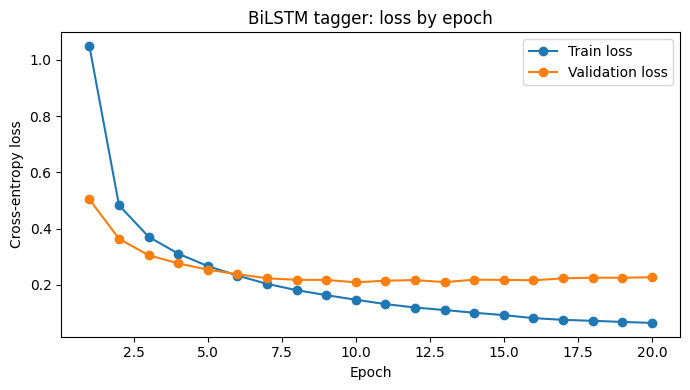

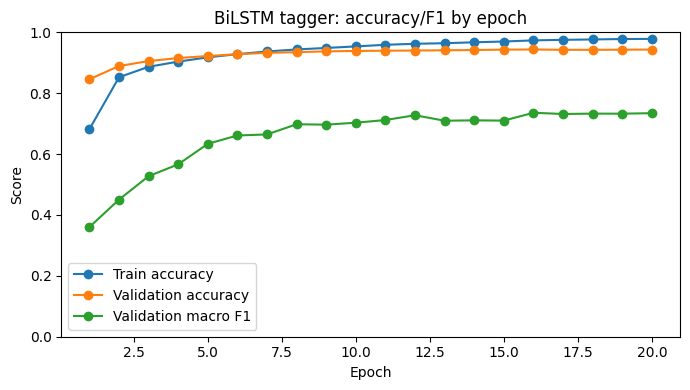

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,val_weighted_f1,lr
0,1,1.049024,0.504541,0.681711,0.845822,0.360238,0.832753,0.0020
1,2,0.483388,0.364283,0.852472,0.889243,0.450371,0.882270,0.0020
2,3,0.371476,0.305788,0.886839,0.905628,0.527482,0.900814,0.0020
3,4,0.311440,0.276831,0.903795,0.915490,0.566344,0.911571,0.0020
4,5,0.267125,0.254302,0.917853,0.922170,0.633790,0.919764,0.0020
5,6,0.233477,0.238469,0.928295,0.928157,0.661166,0.926509,0.0020
6,7,0.204117,0.223831,0.937105,0.932695,0.664555,0.931306,0.0020
7,8,0.181599,0.218483,0.943809,0.934774,0.698081,0.933289,0.0020
8,9,0.163915,0.217975,0.948677,0.937516,0.696675,0.936146,0.0020
9,10,0.147549,0.209545,0.953810,0.938808,0.703091,0.937689,0.0020


BiLSTM validation macro F1: 0.7358
BiLSTM training time: 9.03 minutes


In [13]:
set_seed(SEED)

bilstm_model = BiLSTMTagger(
    vocab_size=vocab_size,
    num_tags=num_tags,
    padding_idx=pad_word_id,
    shape_feature_dim=SHAPE_FEATURE_DIM,
    shape_projection_dim=SHAPE_PROJECTION_DIM,
    **BILSTM_CONFIG,
)

bilstm_model, bilstm_history, bilstm_summary = train_model(
    model=bilstm_model,
    model_name='BiLSTM',
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    pad_label_id=pad_label_id,
    label_ids=real_label_ids,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    max_epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE,
    checkpoint_path=BILSTM_CHECKPOINT_PATH,
)

bilstm_val_metrics = evaluate(
    bilstm_model, val_loader, criterion, device, pad_label_id, real_label_ids, collect_predictions=True
)
plot_training_curves(bilstm_history, 'bilstm', 'BiLSTM tagger', ASSIGNMENT_DIR)

display(bilstm_history)
print(f"BiLSTM validation macro F1: {bilstm_val_metrics['macro_f1']:.4f}")
print(f"BiLSTM training time: {bilstm_summary['elapsed_seconds'] / 60:.2f} minutes")


/var/folders/0p/jl9g9hrx0pn8l7y2_bpp9cn80000gp/T/ipykernel_58399/3353239181.py:54: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)


Transformer  epoch 01 | train loss 2.1167, acc 0.5253 | val loss 0.9370, acc 0.6806, macro F1 0.2992


Transformer  epoch 02 | train loss 0.9670, acc 0.6757 | val loss 0.7991, acc 0.7160, macro F1 0.3533


Transformer  epoch 03 | train loss 0.8349, acc 0.7086 | val loss 0.7302, acc 0.7391, macro F1 0.3938


Transformer  epoch 04 | train loss 0.7644, acc 0.7291 | val loss 0.6898, acc 0.7513, macro F1 0.4147


...

Transformer  epoch 44 | train loss 0.5035, acc 0.8136 | val loss 0.5507, acc 0.7968, macro F1 0.5231


Transformer  epoch 45 | train loss 0.5023, acc 0.8141 | val loss 0.5500, acc 0.7981, macro F1 0.5275


Transformer  epoch 46 | train loss 0.5025, acc 0.8150 | val loss 0.5492, acc 0.7986, macro F1 0.5266


Transformer  epoch 47 | train loss 0.5003, acc 0.8155 | val loss 0.5486, acc 0.7979, macro F1 0.5247


Transformer  epoch 48 | train loss 0.4979, acc 0.8161 | val loss 0.5485, acc 0.7985, macro F1 0.5277
Early stopping Transformer after 48 epochs; best epoch was 43.


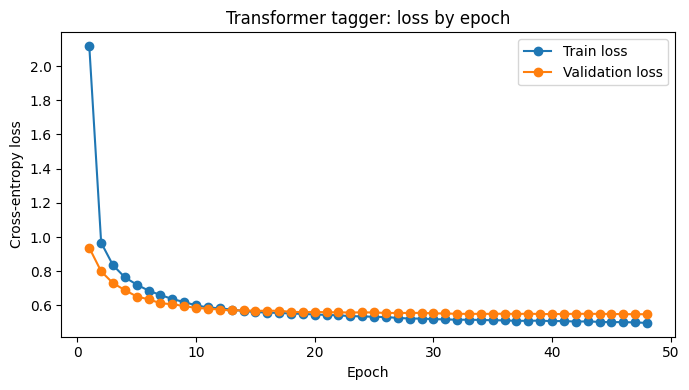

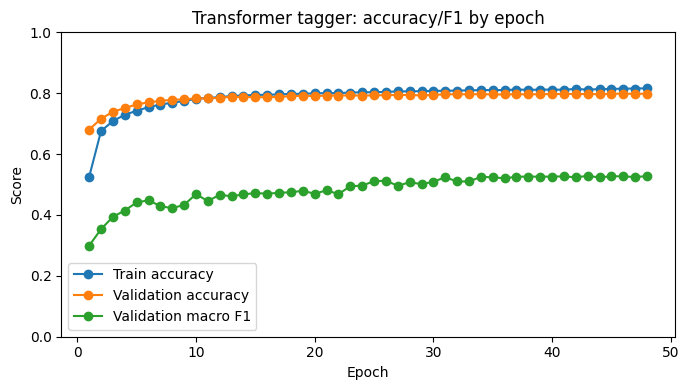

,epoch,train_loss,val_loss,train_accuracy,val_accuracy,val_macro_f1,val_weighted_f1,lr
0,1,2.116688,0.937023,0.525319,0.680615,0.299225,0.660428,0.000500
1,2,0.966995,0.799129,0.675671,0.716001,0.353251,0.701691,0.000500
2,3,0.834853,0.730181,0.708568,0.739066,0.393846,0.725544,0.000500
3,4,0.764398,0.689781,0.729079,0.751260,0.414650,0.741305,0.000500
4,5,0.721517,0.652048,0.742412,0.763045,0.441087,0.754273,0.000500
5,6,0.686682,0.635887,0.754134,0.770166,0.448266,0.762392,0.000500
6,7,0.660869,0.612666,0.762714,0.774767,0.429011,0.766674,0.000500
7,8,0.637354,0.607203,0.768917,0.778264,0.422273,0.770888,0.000500
8,9,0.619653,0.596302,0.774239,0.779966,0.433256,0.773282,0.000250
9,10,0.600186,0.585263,0.781695,0.782644,0.468368,0.776274,0.000250


Transformer validation macro F1: 0.5286
Transformer training time: 3.72 minutes


In [13]:
set_seed(SEED)

transformer_model = TransformerTagger(
    vocab_size=vocab_size,
    num_tags=num_tags,
    padding_idx=pad_word_id,
    shape_feature_dim=SHAPE_FEATURE_DIM,
    shape_projection_dim=SHAPE_PROJECTION_DIM,
    **TRANSFORMER_CONFIG,
    max_len=max(stats['max_len'] + POSITIONAL_ENCODING_BUFFER, TRANSFORMER_MIN_MAX_LEN),
)

transformer_model, transformer_history, transformer_summary = train_model(
    model=transformer_model,
    model_name='Transformer',
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    device=device,
    pad_label_id=pad_label_id,
    label_ids=real_label_ids,
    learning_rate=TRANSFORMER_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    max_epochs=TRANSFORMER_MAX_EPOCHS,
    patience=TRANSFORMER_EARLY_STOPPING_PATIENCE,
    checkpoint_path=TRANSFORMER_CHECKPOINT_PATH,
)

transformer_val_metrics = evaluate(
    transformer_model, val_loader, criterion, device, pad_label_id, real_label_ids, collect_predictions=True
)
plot_training_curves(transformer_history, 'transformer', 'Transformer tagger', ASSIGNMENT_DIR)

display(transformer_history)
print(f"Transformer validation macro F1: {transformer_val_metrics['macro_f1']:.4f}")
print(f"Transformer training time: {transformer_summary['elapsed_seconds'] / 60:.2f} minutes")


The comparison below uses validation macro F1 because the labels are imbalanced and rare chunk types should still influence model selection. Validation loss is used only as a tie-breaker. The selected model is then evaluated once on the held-out test set.


In [15]:
model_results = [
    {
        'model_name': 'BiLSTM',
        'model': bilstm_model,
        'history': bilstm_history,
        'summary': bilstm_summary,
        'validation_metrics': bilstm_val_metrics,
    },
    {
        'model_name': 'Transformer',
        'model': transformer_model,
        'history': transformer_history,
        'summary': transformer_summary,
        'validation_metrics': transformer_val_metrics,
    },
]

results_table = make_results_table(model_results)
display(results_table)

best_name = results_table.iloc[0]['model']
best_result = next(result for result in model_results if result['model_name'] == best_name)
best_model = best_result['model']
print(f"Selected best model: {best_name} (validation macro F1 = {results_table.iloc[0]['val_macro_f1']:.4f})")


,model,best_epoch,val_loss,val_token_accuracy,val_macro_f1,val_weighted_f1,val_matthews_corrcoef,train_time_seconds
0,BiLSTM,16,0.216740,0.943660,0.735762,0.942865,0.929402,541.591422
1,Transformer,43,0.550821,0.797076,0.528628,0.794516,0.746661,223.200000


Selected best model: BiLSTM (validation macro F1 = 0.7358)


---

# 3. **Evaluate models**

The best validation model is evaluated on the untouched test set. Token accuracy measures overall labelling correctness, macro F1 weights all chunk tags equally, weighted F1 reflects performance under the true label distribution, and multiclass Matthews correlation coefficient provides a complementary agreement-style score that is less redundant with precision/recall/F1. The classification report and confusion matrix exclude the padding label.

The row-normalised confusion matrix shows where true labels are assigned to predicted labels. The top-confusion table highlights the largest off-diagonal errors.


In [13]:
def plot_confusion_matrix(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    label_ids: Sequence[int],
    idx_to_tag: Dict[int, str],
    output_path: Path,
    title: str,
) -> pd.DataFrame:
    """Plot and save a row-normalised confusion matrix for the real chunk labels."""
    labels = list(label_ids)
    names = [idx_to_tag[idx] for idx in labels]
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    matrix_df = pd.DataFrame(matrix, index=names, columns=names)
    normalised = matrix_df.div(matrix_df.sum(axis=1).replace(0, np.nan), axis=0).fillna(0.0)

    plt.figure(figsize=CONFUSION_FIGSIZE)
    sns.heatmap(
        normalised,
        cmap='Blues',
        vmin=0,
        vmax=1,
        annot=True,
        fmt='.2f',
        square=True,
        cbar_kws={'label': 'Row-normalised proportion'},
    )
    plt.xlabel('Predicted label')
    plt.ylabel('True label')
    plt.title(title)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches='tight')
    plt.show()
    plt.close()
    return matrix_df


def top_confusions(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    label_ids: Sequence[int],
    idx_to_tag: Dict[int, str],
    top_n: int = TOP_CONFUSIONS,
) -> pd.DataFrame:
    """Return the largest off-diagonal confusion counts for concise discussion."""
    matrix = confusion_matrix(y_true, y_pred, labels=list(label_ids))
    rows = []
    for true_pos, true_id in enumerate(label_ids):
        for pred_pos, pred_id in enumerate(label_ids):
            if true_id == pred_id:
                continue
            count = int(matrix[true_pos, pred_pos])
            if count:
                rows.append({
                    'true_label': idx_to_tag[true_id],
                    'predicted_label': idx_to_tag[pred_id],
                    'count': count,
                })
    return pd.DataFrame(rows).sort_values('count', ascending=False).head(top_n).reset_index(drop=True)


,metric,value
0,token_accuracy,0.942984
1,macro_f1,0.752093
2,weighted_f1,0.942322
3,matthews_corrcoef,0.928787
4,macro_precision,0.796359
5,macro_recall,0.722956
6,loss,0.215831


              precision    recall  f1-score   support

      B-ADJP     0.7239    0.6025    0.6576       322
      B-ADVP     0.8189    0.7783    0.7981       645
     B-CONJP     0.6667    0.4444    0.5333         9
      B-INTJ     0.0000    0.0000    0.0000         2
        B-NP     0.9528    0.9530    0.9529      8321
        B-PP     0.9626    0.9715    0.9670      3156
       B-PRT     0.7895    0.7229    0.7547        83
      B-SBAR     0.8709    0.8923    0.8815       325
        B-VP     0.9525    0.9207    0.9363      3266
      I-ADJP     0.7333    0.5392    0.6215       102
      I-ADVP     0.6667    0.5714    0.6154        63
     I-CONJP     0.6000    0.7500    0.6667        12
        I-NP     0.9378    0.9687    0.9530      9431
        I-PP     0.9688    0.5849    0.7294        53
      I-SBAR     1.0000    0.7143    0.8333         7
        I-VP     0.9212    0.9252    0.9232      1806
           O     0.9727    0.9508    0.9616      4230

    accuracy              

,precision,recall,f1-score,support
B-ADJP,0.723881,0.602484,0.657627,322.000000
B-ADVP,0.818923,0.778295,0.798092,645.000000
B-CONJP,0.666667,0.444444,0.533333,9.000000
B-INTJ,0.000000,0.000000,0.000000,2.000000
B-NP,0.952781,0.953010,0.952896,8321.000000
B-PP,0.962637,0.971483,0.967040,3156.000000
B-PRT,0.789474,0.722892,0.754717,83.000000
B-SBAR,0.870871,0.892308,0.881459,325.000000
B-VP,0.952487,0.920698,0.936323,3266.000000
I-ADJP,0.733333,0.539216,0.621469,102.000000


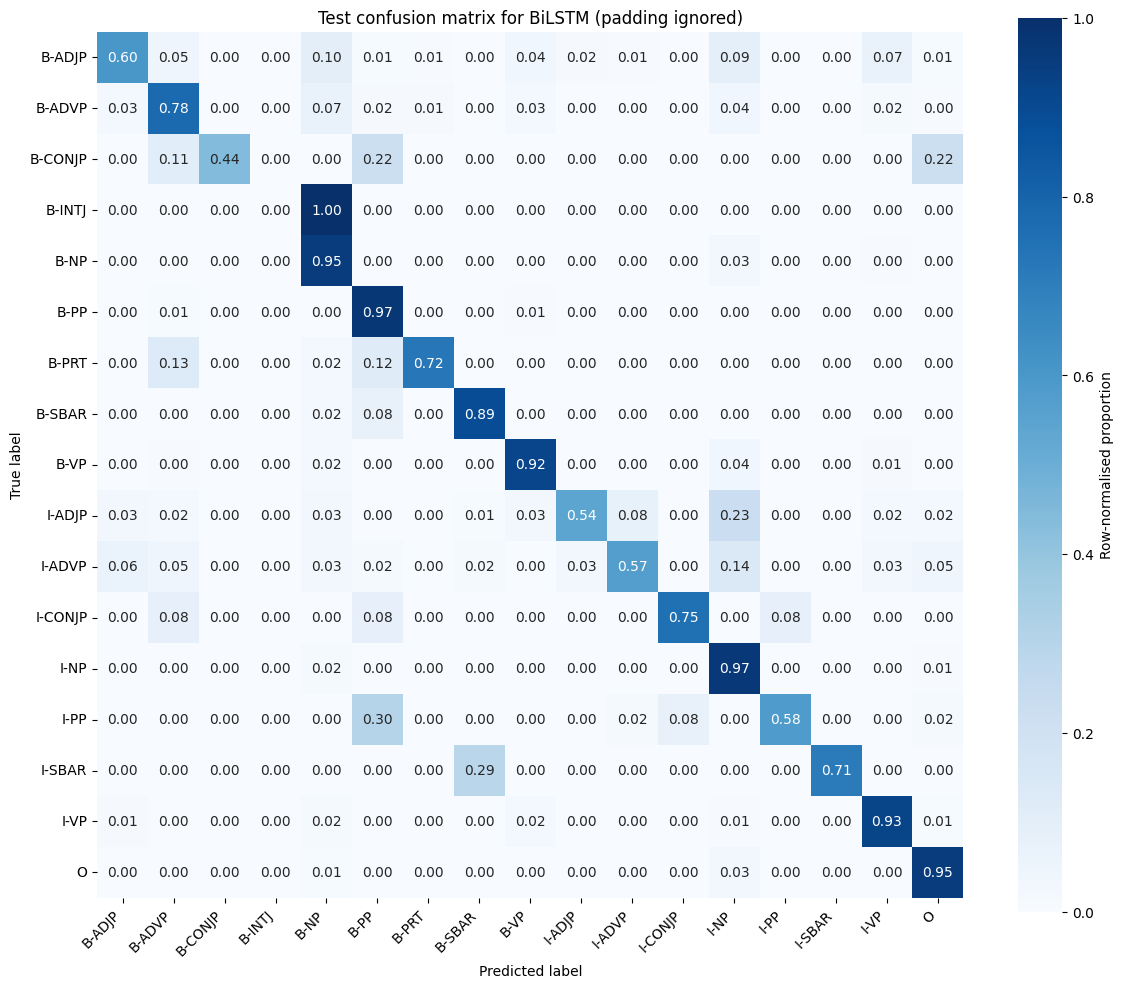

,true_label,predicted_label,count
0,B-NP,I-NP,262
1,I-NP,B-NP,156
2,O,I-NP,120
3,B-VP,I-NP,117
4,I-NP,O,69
5,B-VP,B-NP,65
6,B-ADVP,B-NP,47
7,B-VP,I-VP,45


In [16]:
test_metrics = evaluate(
    best_model, test_loader, criterion, device, pad_label_id, real_label_ids, collect_predictions=True
)

test_summary = pd.DataFrame({
    'metric': [
        'token_accuracy',
        'macro_f1',
        'weighted_f1',
        'matthews_corrcoef',
        'macro_precision',
        'macro_recall',
        'loss',
    ],
    'value': [
        test_metrics['accuracy'],
        test_metrics['macro_f1'],
        test_metrics['weighted_f1'],
        test_metrics['matthews_corrcoef'],
        test_metrics['macro_precision'],
        test_metrics['macro_recall'],
        test_metrics['loss'],
    ],
})
display(test_summary)

report_text = classification_report(
    test_metrics['labels'],
    test_metrics['predictions'],
    labels=real_label_ids,
    target_names=real_label_names,
    digits=4,
    zero_division=0,
)
print(report_text)

report_dict = classification_report(
    test_metrics['labels'],
    test_metrics['predictions'],
    labels=real_label_ids,
    target_names=real_label_names,
    output_dict=True,
    zero_division=0,
)
classification_report_df = pd.DataFrame(report_dict).T

display(classification_report_df)

confusion_counts = plot_confusion_matrix(
    test_metrics['labels'],
    test_metrics['predictions'],
    real_label_ids,
    idx_to_tag,
    CONFUSION_MATRIX_PATH,
    f'Test confusion matrix for {best_name} (padding ignored)',
)

top_confusion_table = top_confusions(
    test_metrics['labels'], test_metrics['predictions'], real_label_ids, idx_to_tag, top_n=TOP_CONFUSIONS
)
display(top_confusion_table)
